#  Hotel Bookings — EDA, Data Cleaning & Missing Value Treatment

In [28]:
#importing libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

In [29]:
df = pd.read_csv("hotel_bookings.csv", keep_default_na=False)

In [30]:
#Check first 10 rows
df.head(10)

,booking_id,customer_id,customer_name,customer_segment,customer_signup_date,customer_home_city,customer_loyalty_tier,property_id,property_name,property_city,...,nights,booking_channel,adr,discount_amount,coupon_code,total_amount,payment_method,booking_status,review_rating,review_date
0,100000,424,Customer_424,Group,03-07-2023,Manali,Platinum,38,Crimson Courtyard,Manali,...,4,OTA,5808.46,0.00,NONE,46467.68,Debit Card,Cancelled,,
1,100001,239,Customer_239,Individual,18-07-2022,Jaipur,None,32,Saffron Palace,Pune,...,4,Corporate Portal,4021.62,0.00,,16086.48,Net Banking,Cancelled,,
2,100002,301,Customer_301,Corporate,05-07-2023,Jaipur,Gold,53,Saffron Heights,Chennai,...,3,Corporate Portal,17663.11,15373.35,SAVE10,90605.31,Net Banking,Completed,,
3,100003,722,Customer_722,Individual,07-11-2022,Udaipur,None,43,Indigo Lodge,Bangalore,...,3,OTA,5885.85,0.00,NONE,17657.55,Credit Card,No-Show,,
4,100004,306,Customer_306,Corporate,02-02-2022,Udaipur,Silver,29,Cedar Lodge,Kochi,...,7,Direct Website,6199.44,5924.82,SAVE10,80867.34,Credit Card,Completed,6,21-11-2024
5,100005,396,Customer_396,Individual,04-06-2022,Kochi,None,6,Hilltop Inn,Udaipur,...,4,Corporate Portal,28475.74,16492.59,WELCOME,97410.37,Net Banking,Cancelled,,
6,100006,326,Customer_326,Corporate,21-12-2023,Kochi,Gold,37,Olive Lodge,Udaipur,...,2,OTA,3286.32,2625.92,WELCOME,10519.36,Debit Card,Completed,,
7,100007,85,Customer_85,Individual,25-07-2022,Udaipur,None,45,Cedar Heights,Udaipur,...,2,Corporate Portal,4152.34,0.00,,8304.68,Credit Card,Completed,3,13-07-2024
8,100008,318,Customer_318,Individual,10-06-2023,Manali,Platinum,35,Maple Retreat,Bangalore,...,3,Corporate Portal,8795.64,2472.47,FEST15,23914.45,Credit Card,Completed,,
9,100009,424,Customer_424,Group,03-07-2023,Manali,Platinum,11,Coral Palace,Mumbai,...,7,OTA,10413.32,0.00,NONE,145786.48,UPI,Completed,,


In [31]:
#Check last 10 rows
df.tail(10)

,booking_id,customer_id,customer_name,customer_segment,customer_signup_date,customer_home_city,customer_loyalty_tier,property_id,property_name,property_city,...,nights,booking_channel,adr,discount_amount,coupon_code,total_amount,payment_method,booking_status,review_rating,review_date
11990,111990,521,Customer_521,Individual,14-05-2022,Udaipur,None,41,Marigold Residency,Pune,...,3,Corporate Portal,5440.82,1608.29,SAVE10,14714.17,Debit Card,Completed,5,19-04-2024
11991,111991,140,Customer_140,Individual,04-09-2023,Udaipur,Silver,37,Olive Lodge,Udaipur,...,1,Direct Website,2730.56,0.00,NONE,2730.56,Net Banking,Completed,,
11992,111992,448,Customer_448,Group,27-06-2022,Udaipur,Platinum,5,Hilltop Inn,Chennai,...,1,Corporate Portal,2947.51,1212.88,APPDEAL,7629.65,Debit Card,Completed,,
11993,111993,638,Customer_638,Individual,27-09-2023,Udaipur,None,42,Coral Suites,Chennai,...,2,Direct Website,2980.75,445.22,FEST15,5516.28,UPI,Completed,5,29-06-2024
11994,111994,736,Customer_736,Individual,31-01-2023,Bangalore,Silver,19,Marigold Palace,Delhi,...,2,Corporate Portal,5629.68,813.51,SAVE10,10445.85,Net Banking,Completed,3,15-07-2024
11995,111995,700,Customer_700,Individual,14-04-2023,Pune,Silver,50,Jade Palace,Chennai,...,3,OTA,7771.11,0.00,,23313.33,Credit Card,No-Show,,
11996,111996,642,Customer_642,Corporate,12-10-2022,Manali,Silver,46,Coral Manor,Kochi,...,3,Corporate Portal,1945.41,0.00,NONE,17508.69,Net Banking,Completed,6,15-05-2024
11997,111997,82,Customer_82,Corporate,11-07-2022,Delhi,None,44,Amber Lodge,Udaipur,...,3,Direct Website,5791.65,0.00,NONE,34749.90,Net Banking,Completed,,
11998,111998,563,Customer_563,Corporate,12-10-2023,Manali,Silver,35,Maple Retreat,Bangalore,...,4,Corporate Portal,12285.15,0.00,,49140.60,Credit Card,Completed,7,31-05-2024
11999,111999,760,Customer_760,Individual,25-10-2023,Bangalore,Platinum,12,Sapphire Courtyard,Pune,...,2,Direct Website,5504.82,0.00,,11009.64,Debit Card,Completed,,


In [32]:
# Check Shape
df.shape

(12000, 28)

## The dataset contains 12,000 booking records and 28 variables representing customer details, property information, booking details, pricing and discounts, payment information, booking channels, customer reviews, and booking outcomes.

In [33]:
# Dataset Information
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12000 entries, 0 to 11999
Data columns (total 28 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   booking_id             12000 non-null  int64  
 1   customer_id            12000 non-null  int64  
 2   customer_name          12000 non-null  object 
 3   customer_segment       12000 non-null  object 
 4   customer_signup_date   12000 non-null  object 
 5   customer_home_city     12000 non-null  object 
 6   customer_loyalty_tier  12000 non-null  object 
 7   property_id            12000 non-null  int64  
 8   property_name          12000 non-null  object 
 9   property_city          12000 non-null  object 
 10  property_star_rating   12000 non-null  int64  
 11  property_type          12000 non-null  object 
 12  property_total_rooms   12000 non-null  int64  
 13  booking_date           12000 non-null  object 
 14  checkin_date           12000 non-null  object 
 15  ch

In [34]:
#Missing Values
df.isnull().sum().sum()

np.int64(0)

## This dataset has 0 null values.

In [35]:
#Statistical Summary
df.describe()

,booking_id,customer_id,property_id,property_star_rating,property_total_rooms,num_rooms,nights,adr,discount_amount,total_amount
count,12000.00000,12000.000000,12000.000000,12000.000000,12000.000000,12000.000000,12000.000000,12000.000000,12000.000000,12000.000000
mean,105999.50000,399.371250,27.936833,3.633917,87.582500,1.442833,2.850250,8033.759119,1722.596401,31313.479270
std,3464.24595,230.356836,15.991205,1.084588,38.491612,0.894035,1.523708,6882.096052,5472.858618,44217.972507
min,100000.00000,1.000000,1.000000,2.000000,30.000000,0.000000,1.000000,1619.950000,0.000000,0.000000
25%,102999.75000,201.000000,14.000000,3.000000,60.000000,1.000000,2.000000,3677.615000,0.000000,8926.725000
50%,105999.50000,400.000000,28.000000,4.000000,80.000000,1.000000,3.000000,5724.160000,0.000000,17274.720000
75%,108999.25000,596.000000,42.000000,5.000000,120.000000,2.000000,4.000000,9765.242500,1309.595000,35677.547500
max,111999.00000,800.000000,60.000000,5.000000,200.000000,5.000000,7.000000,63851.460000,174504.110000,925274.700000


### The descriptive statistics provide an overview of booking revenue and pricing distribution

In [36]:
#Checking the datatypes of the data
print(df.dtypes)

booking_id                 int64
customer_id                int64
customer_name             object
customer_segment          object
customer_signup_date      object
customer_home_city        object
customer_loyalty_tier     object
property_id                int64
property_name             object
property_city             object
property_star_rating       int64
property_type             object
property_total_rooms       int64
booking_date              object
checkin_date              object
checkout_date             object
room_type                 object
num_rooms                  int64
nights                     int64
booking_channel           object
adr                      float64
discount_amount          float64
coupon_code               object
total_amount             float64
payment_method            object
booking_status            object
review_rating             object
review_date               object
dtype: object


# Feature Engineering

In [37]:
#Conversion of the datatypes of column.
date_cols = [
    'customer_signup_date',
    'booking_date',
    'checkin_date',
    'checkout_date',
    'review_date'
]

for col in date_cols:
    df[col] = pd.to_datetime(
        df[col],
        format='%d-%m-%Y',
        errors='coerce'
    )


In [38]:
#conversion of review rating to numeric
df['review_rating'] = pd.to_numeric(
    df['review_rating'],
    errors='coerce'
)

In [39]:
#Checking the datatypes of the data
print(df.dtypes)

booking_id                        int64
customer_id                       int64
customer_name                    object
customer_segment                 object
customer_signup_date     datetime64[ns]
customer_home_city               object
customer_loyalty_tier            object
property_id                       int64
property_name                    object
property_city                    object
property_star_rating              int64
property_type                    object
property_total_rooms              int64
booking_date             datetime64[ns]
checkin_date             datetime64[ns]
checkout_date            datetime64[ns]
room_type                        object
num_rooms                         int64
nights                            int64
booking_channel                  object
adr                             float64
discount_amount                 float64
coupon_code                      object
total_amount                    float64
payment_method                   object


In [40]:
#Check duplicated records.
df[df.duplicated(subset=['booking_id'], keep=False)]

,booking_id,customer_id,customer_name,customer_segment,customer_signup_date,customer_home_city,customer_loyalty_tier,property_id,property_name,property_city,...,nights,booking_channel,adr,discount_amount,coupon_code,total_amount,payment_method,booking_status,review_rating,review_date


### This shows that there is no duplicated value in the dataset.

# Section -1 Data Quality Checks

## A1. Invalid Stays

In [41]:
invalid_stays = df[df['checkout_date'] <= df['checkin_date']]

print("Invalid Stay Records:", len(invalid_stays))

Invalid Stay Records: 120


## A2. Compute review rating range and mean separately for each customer segment. What does this reveal? (1-line implication)

In [42]:
#Normalizing the Rating by converting them to Percent.
df['review_rating_normalized'] = np.where(
    df['customer_segment'] == 'Corporate',
    (df['review_rating'] /2),   # Corporate scale: 1-10
    df['review_rating']     # Individual & Group scale: 1-5
)

In [43]:
review_stats = (
    df.groupby('customer_segment')['review_rating_normalized']
      .agg(
          rating_min='min',
          rating_max='max',
          rating_mean='mean'
      )
      .reset_index()
)

review_stats['rating_mean'] = review_stats['rating_mean'].round(2)

print(review_stats)

  customer_segment  rating_min  rating_max  rating_mean
0        Corporate         1.5         5.0         3.62
1            Group         1.0         5.0         3.77
2       Individual         1.0         5.0         3.77


### After normalizing the review scale, Group and Individual customers have slightly higher average ratings (3.77/5) than Corporate customers (3.62/5), indicating marginally lower satisfaction among Corporate guests.

## A3. After applying the relevant data-quality footnotes, what is realized revenue for property type "Luxury" in Rupees? 

In [44]:
valid_rows = (
    (df['checkout_date'] > df['checkin_date']) &      # Footnote 1
    (df['booking_date'] >= df['customer_signup_date']) &  # Footnote 2
    (df['num_rooms'] > 0)                             # Footnote 3
)

realized_revenue_luxury = (
    df.loc[
        valid_rows &
        (df['booking_status'] == 'Completed') &       # Footnote 8
        (df['property_type'] == 'Luxury'),
        'total_amount'
    ].sum()
)

print(f"₹{realized_revenue_luxury:,.2f}")

₹89,009,636.79


### Total Revenue after applying Footnotes 1, 2, 3, and 8 is **₹89,009,636.79**

# Section 2 Case Study: The Cancellation Crisis

## A1. Cancellation Landscape

In [45]:
#Cancelled Percentage
total_bookings = len(df)

cancelled_bookings = len(
    df[df['booking_status'] == 'Cancelled']
)

cancellation_rate = (
    cancelled_bookings / total_bookings
) * 100

print(round(cancellation_rate, 2))

19.18


### The overall Cancellation Rate is 19.18%.

In [46]:
channel_cancel = (
    df.groupby('booking_channel')['booking_status']
      .apply(lambda x: (x == 'Cancelled').mean() * 100)
      .reset_index(name='cancellation_rate')
      .sort_values('cancellation_rate', ascending=False)
)

print(channel_cancel)

    booking_channel  cancellation_rate
2               OTA          22.073027
0  Corporate Portal          20.230314
3      Travel Agent          16.528583
1    Direct Website          14.849624


### OTA and Corporate Portal bookings have the highest cancellation rates (22.1% and 20.2%), while Direct Website bookings show the lowest cancellation rate (14.9%), making them the most reliable booking channel.

In [47]:
df['is_cancelled'] = df['booking_status'].eq('Cancelled')
df['lead_time_days'] = (df['checkin_date'] - df['booking_date']).dt.days
df['lead_bucket'] = pd.cut(
    df['lead_time_days'],
    bins=[-9999, 0, 7, 30, 60, 120, 99999],
    labels=['<=0', '1-7', '8-30', '31-60', '61-120', '121+']
)

# Core KPIs
platform_rate = df['is_cancelled'].mean()
benchmark_rate = 0.12
target_rate = 0.14

print('Platform cancellation rate:', round(platform_rate * 100, 2), '%')
print('Benchmark rate:', round(benchmark_rate * 100, 2), '%')
print('Target rate:', round(target_rate * 100, 2), '%')
print('Gap to benchmark:', round((platform_rate - benchmark_rate) * 100, 2), 'percentage points')


Platform cancellation rate: 19.18 %
Benchmark rate: 12.0 %
Target rate: 14.0 %
Gap to benchmark: 7.18 percentage points


In [48]:
# Lead-time summary
#Lead time is the number of days between the booking and actual 
lead_summary = df.groupby('lead_bucket', observed=False).agg(
    bookings=('booking_id', 'size'),
    cancels=('is_cancelled', 'sum')
).reset_index()

lead_summary['cancel_rate'] = lead_summary['cancels'] / lead_summary['bookings']
lead_summary['lead_bucket'] = pd.Categorical(
    lead_summary['lead_bucket'],
    categories=['<=0', '1-7', '8-30', '31-60', '61-120', '121+'],
    ordered=True
)
lead_summary = lead_summary.sort_values('lead_bucket')

print('\nLead-time summary:')
print(lead_summary)


Lead-time summary:
  lead_bucket  bookings  cancels  cancel_rate
0         <=0         0        0          NaN
1         1-7      4065      709     0.174416
2        8-30      4248      736     0.173258
3       31-60      2620      629     0.240076
4      61-120       940      206     0.219149
5        121+       127       22     0.173228


C:\Users\saini\AppData\Local\Temp\ipykernel_18208\2051081188.py:3: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df.groupby(['booking_channel', 'lead_bucket'])['booking_status']


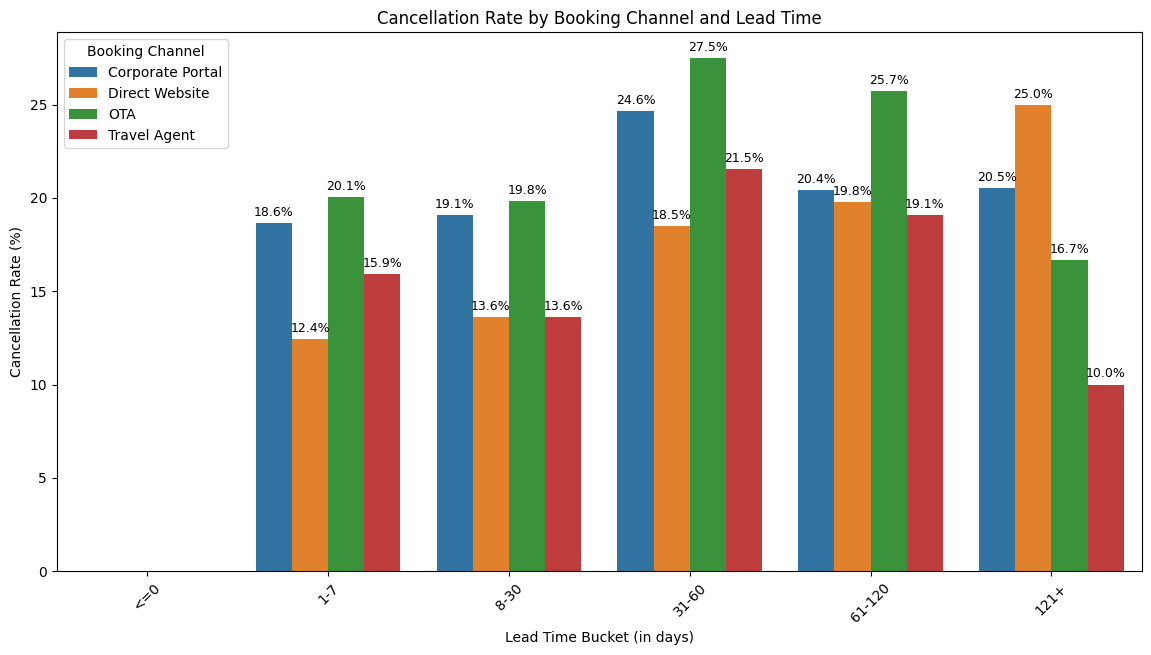

In [49]:
#Cancellation Rate by Booking Channel and Lead Time Bucket
cancel_rate = (
    df.groupby(['booking_channel', 'lead_bucket'])['booking_status']
      .apply(lambda x: (x == 'Cancelled').mean() * 100)
      .reset_index(name='cancellation_rate')
)


# Plot
plt.figure(figsize=(14,7))
ax= sns.barplot(
    data=cancel_rate,
    x='lead_bucket',
    y='cancellation_rate',
    hue='booking_channel'
)
for container in ax.containers:
    ax.bar_label(
        container,
        fmt='%.1f%%',      # show percentage with 1 decimal
        padding=3,
        fontsize=9
    )
plt.title('Cancellation Rate by Booking Channel and Lead Time')
plt.xlabel('Lead Time Bucket (in days)')
plt.ylabel('Cancellation Rate (%)')
plt.legend(title='Booking Channel')
plt.xticks(rotation=45)
plt.savefig("1.jpeg")
plt.show()


### OTA  have the highest cancellation rates (22.1%)

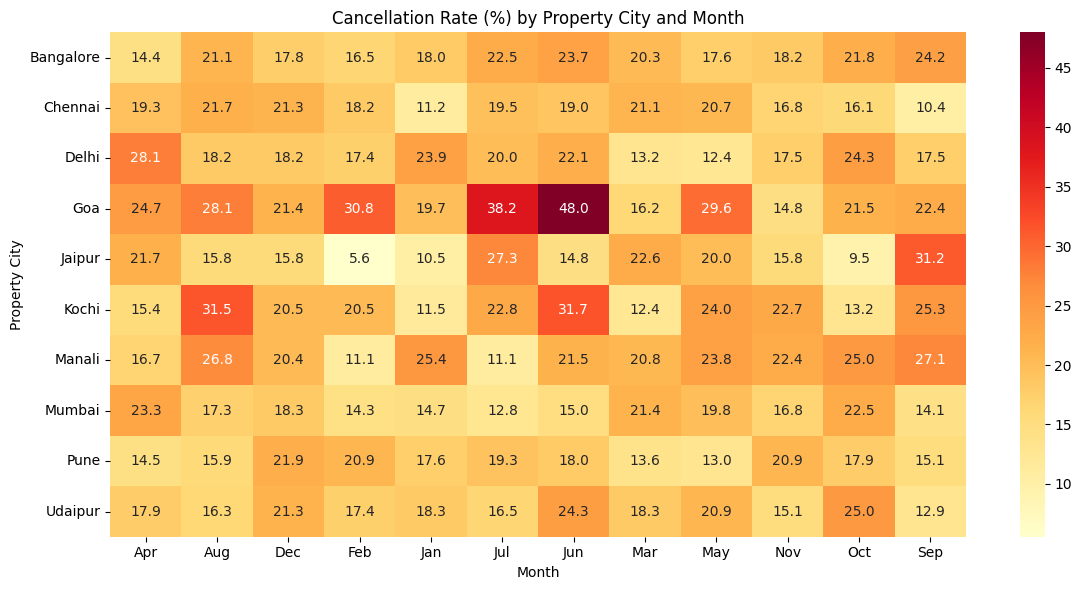

In [50]:
#Cancellation Rate Analysis: Property City × Calendar Month 


df['booking_month'] = pd.to_datetime(df['booking_date']).dt.strftime('%b')


city_month_cancel = (
    df.groupby(['property_city', 'booking_month'])['booking_status']
      .apply(lambda x: (x == 'Cancelled').mean() * 100)
      .reset_index(name='cancellation_rate')
)

# Create pivot table for heatmap
heatmap_data = city_month_cancel.pivot(
    index='property_city',
    columns='booking_month',
    values='cancellation_rate'
)

# Plot heatmap
plt.figure(figsize=(12, 6))
sns.heatmap(
    heatmap_data,
    annot=True,
    fmt='.1f',
    cmap='YlOrRd'
)

plt.title('Cancellation Rate (%) by Property City and Month')
plt.xlabel('Month')
plt.ylabel('Property City')
plt.tight_layout()
plt.savefig("2.jpeg")
plt.show()


### Goa is a major hotspot with a cancellation rate significantly above platform average that is in the Month of June.

In [51]:
table1 = cancel_rate.groupby('booking_channel')['cancellation_rate'].mean().sort_values(ascending=False)
pd.DataFrame(table1)

,cancellation_rate
booking_channel,
OTA,21.960281
Corporate Portal,20.658189
Direct Website,17.870124
Travel Agent,16.023378


In [52]:
# table2= city_channel_cancel.groupby(['property_city', 'booking_month'])['cancellation_rate'].mean().sort_values(ascending=False)
# pd.DataFrame(table2)
df['booking_month'] = pd.to_datetime(df['booking_date']).dt.strftime('%b')

city_month_cancel = (
    df.groupby(['property_city', 'booking_month'])['booking_status']
      .apply(lambda x: (x == 'Cancelled').mean() * 100)
      .reset_index(name='cancellation_rate')
)

table2 = city_month_cancel.sort_values(
    'cancellation_rate',
    
    ascending=False
).round(2)

table2

,property_city,booking_month,cancellation_rate
42,Goa,Jun,48.00
41,Goa,Jul,38.16
66,Kochi,Jun,31.67
61,Kochi,Aug,31.51
59,Jaipur,Sep,31.25
...,...,...,...
77,Manali,Jul,11.11
52,Jaipur,Jan,10.53
23,Chennai,Sep,10.43
58,Jaipur,Oct,9.52


### The slice that most strongly separates high-cancel from low-cancel bookings is property city by calendar month, which shows a much wider cancellation spread than booking channel by lead-time bucket. 

## A2 Rate vs. Volume.

In [53]:
# 1. Top 3 Slices by Cancellation Rate
city_month_cancel = (
    df.groupby(['property_city', 'booking_month'])
      .agg(
          total_bookings=('booking_id', 'count'),
          cancelled_bookings=('booking_status',
                              lambda x: (x == 'Cancelled').sum())
      )
      .reset_index()
)

city_month_cancel['cancellation_rate'] = (
    city_month_cancel['cancelled_bookings']
    / city_month_cancel['total_bookings']
    * 100
).round(2)
top_3_rate = (
    city_month_cancel
    .sort_values('cancellation_rate', ascending=False)
    .head(3)
    [['property_city',
      'booking_month',
      'total_bookings',
      'cancelled_bookings',
      'cancellation_rate']]
)

top_3_rate

,property_city,booking_month,total_bookings,cancelled_bookings,cancellation_rate
42,Goa,Jun,75,36,48.00
41,Goa,Jul,76,29,38.16
66,Kochi,Jun,60,19,31.67


In [54]:
# 2. Top 3 Slices by Cancellation Count
top_count = (
    city_month_cancel
    .sort_values('cancelled_bookings', ascending=False)
    .head(3)
)

top_count[['property_city',
           'booking_month',
           'cancelled_bookings',
           'total_bookings',
           'cancellation_rate']]

,property_city,booking_month,cancelled_bookings,total_bookings,cancellation_rate
105,Pune,Nov,37,177,20.90
19,Chennai,Mar,36,171,21.05
42,Goa,Jun,36,75,48.00


### No. High-rate slices and high-volume slices are often not the same. A slice can have a very high cancellation rate but relatively few bookings, resulting in a small number of cancellations overall.
### This distinction matters because the board's goal is to reduce the platform-wide cancellation rate by 5 percentage points. To achieve that, interventions should focus on slices with the largest number of cancellations (high volume), since reducing cancellations in small-volume, high-rate segments may have little impact on the overall platform metric.

## A3 Root Cause: Hypothesis Testing.

In [55]:
df = pd.read_csv("hotel_bookings.csv")
# Convert dates
date_cols = ['booking_date', 'checkin_date']
for col in date_cols:
    df[col] = pd.to_datetime(df[col], dayfirst=True)
# Lead time
df['lead_time'] = (df['checkin_date'] - df['booking_date']).dt.days

# Month
df['month'] = df['checkin_date'].dt.month_name()

# Cancellation Flag
df['is_cancelled'] = (df['booking_status'] == 'Cancelled').astype(int)
goa_june = df[
    (df['property_city'] == 'Goa') &
    (df['month'] == 'June')
]

rest_platform = df[
    ~(
        (df['property_city'] == 'Goa') &
        (df['month'] == 'June')
    )
]

comparison = pd.DataFrame({
    'Metric': ['Mean Lead Time', 'Median Lead Time'],
    'Goa June': [
        round(goa_june['lead_time'].mean(),2),
        round(goa_june['lead_time'].median(),2)
    ],
    'Rest Platform': [
        round(rest_platform['lead_time'].mean(),2),
        round(rest_platform['lead_time'].median(),2)
    ]
})

print(comparison)

             Metric  Goa June  Rest Platform
0    Mean Lead Time     38.21          32.52
1  Median Lead Time     15.00          15.00


In [56]:
t_stat, p_value = stats.ttest_ind(
    goa_june['lead_time'].dropna(),
    rest_platform['lead_time'].dropna(),
    equal_var=False
)

print("T-statistic:", round(t_stat,3))
print("P-value:", round(p_value,4))

T-statistic: 0.404
P-value: 0.6875


In [57]:
# Goa June
goa_june = df[
    (df['property_city'] == 'Goa') &
    (df['month'] == 'June')
]

# Rest of platform
rest_platform = df[
    ~(
        (df['property_city'] == 'Goa') &
        (df['month'] == 'June')
    )
]

# Channel distribution
goa_channel_mix = (
    goa_june['booking_channel']
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

rest_channel_mix = (
    rest_platform['booking_channel']
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

channel_comparison = pd.concat(
    [goa_channel_mix, rest_channel_mix],
    axis=1
)

channel_comparison.columns = [
    'Goa June %',
    'Rest Platform %'
]

channel_comparison.fillna(0)

,Goa June %,Rest Platform %
booking_channel,,
OTA,36.84,35.37
Corporate Portal,28.07,26.77
Travel Agent,22.81,20.10
Direct Website,12.28,17.76


In [58]:
channel_cancel = (
    df.groupby('booking_channel')
      .agg(
          bookings=('booking_id','count'),
          cancellations=('is_cancelled','sum')
      )
)

channel_cancel['cancel_rate'] = (
    channel_cancel['cancellations']
    / channel_cancel['bookings']
    * 100
).round(2)

channel_cancel.sort_values(
    'cancel_rate',
    ascending=False
)

,bookings,cancellations,cancel_rate
booking_channel,,,
OTA,4245,937,22.07
Corporate Portal,3213,650,20.23
Travel Agent,2414,399,16.53
Direct Website,2128,316,14.85


In [59]:
goa_monthly = (
    df[df['property_city'] == 'Goa']
      .groupby('month')
      .agg(
          bookings=('booking_id','count'),
          cancellations=('is_cancelled','sum')
      )
)

goa_monthly['cancel_rate'] = (
    goa_monthly['cancellations']
    / goa_monthly['bookings']
    * 100
).round(2)

goa_monthly.sort_values(
    'cancel_rate',
    ascending=False
)

,bookings,cancellations,cancel_rate
month,,,
June,57,30,52.63
August,88,39,44.32
July,65,24,36.92
March,70,21,30.00
September,81,19,23.46
February,77,18,23.38
October,76,17,22.37
November,72,15,20.83
May,80,16,20.00


In [60]:
goa_june_rate = goa_monthly.loc['June','cancel_rate']

goa_other_rate = (
    df[
        (df['property_city']=='Goa') &
        (df['month']!='June')
    ]['is_cancelled']
    .mean()*100
)

print("Goa June:", round(goa_june_rate,2))
print("Goa Other Months:", round(goa_other_rate,2))

Goa June: 52.63
Goa Other Months: 24.46


In [61]:
june_city_rates = (
    df[df['month']=='June']
      .groupby('property_city')
      .agg(
          bookings=('booking_id','count'),
          cancellations=('is_cancelled','sum')
      )
)

june_city_rates['cancel_rate'] = (
    june_city_rates['cancellations']
    / june_city_rates['bookings']
    * 100
).round(2)

june_city_rates.sort_values(
    'cancel_rate',
    ascending=False
)

,bookings,cancellations,cancel_rate
property_city,,,
Goa,57,30,52.63
Kochi,70,22,31.43
Manali,67,17,25.37
Jaipur,33,7,21.21
Chennai,160,33,20.62
Udaipur,129,26,20.16
Bangalore,137,25,18.25
Mumbai,107,19,17.76
Delhi,80,12,15.00


In [62]:
from scipy.stats import chi2_contingency

goa_june_cancel = goa_june['is_cancelled'].sum()
goa_june_not = len(goa_june) - goa_june_cancel

others_cancel = rest_platform['is_cancelled'].sum()
others_not = len(rest_platform) - others_cancel

contingency = [
    [goa_june_cancel, goa_june_not],
    [others_cancel, others_not]
]

chi2, p, dof, exp = chi2_contingency(contingency)

print("p-value:", round(p,4))

p-value: 0.0


## Diagonsis

In [63]:
# Goa June
goa_june = df[
    (df['property_city'] == 'Goa') &
    (df['month'] == 'June')
]

# Goa Other Months
goa_other = df[
    (df['property_city'] == 'Goa') &
    (df['month'] != 'June')
]

# Other Cities June
other_cities_june = df[
    (df['property_city'] != 'Goa') &
    (df['month'] == 'June')
]

# Platform
platform = df

diagnosis_df = pd.DataFrame({
    'Group': [
        'Goa June',
        'Goa Other Months',
        'Other Cities June',
        'Platform Average'
    ],
    'Cancellation Rate': [
        round(goa_june['is_cancelled'].mean()*100, 2),
        round(goa_other['is_cancelled'].mean()*100, 2),
        round(other_cities_june['is_cancelled'].mean()*100, 2),
        round(platform['is_cancelled'].mean()*100, 2)
    ]
})

print(diagnosis_df)

               Group  Cancellation Rate
0           Goa June              52.63
1   Goa Other Months              24.46
2  Other Cities June              19.52
3   Platform Average              19.18


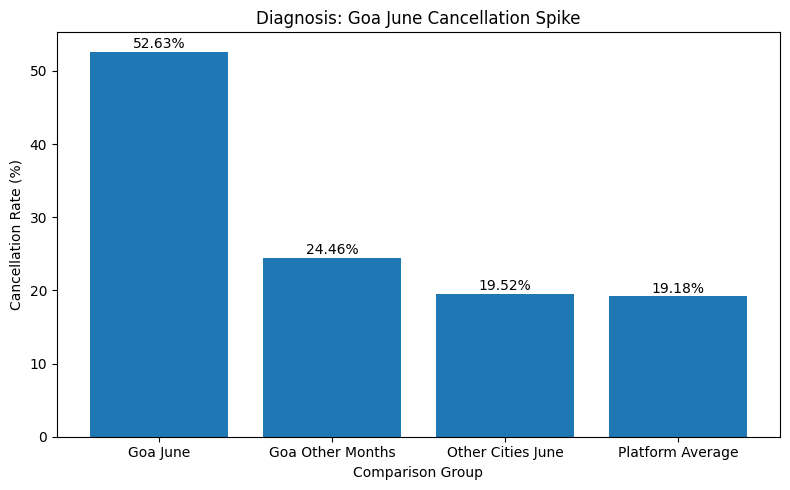

In [65]:
plt.figure(figsize=(8,5))

bars = plt.bar(
    diagnosis_df['Group'],
    diagnosis_df['Cancellation Rate']
)

plt.title('Diagnosis: Goa June Cancellation Spike')
plt.ylabel('Cancellation Rate (%)')
plt.xlabel('Comparison Group')

for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width()/2,
        height + 0.5,
        f'{height:.2f}%',
        ha='center'
    )

plt.tight_layout()
plt.savefig("3.jpeg")
plt.show()
